# Case 5 with firm reserve: bid and allocation
## 1. Marginal distribution assumptions
This notebook follows Case5's imports, marginal assumptions, scenario configuration, dependence assumptions, Stage 1 aggregate benchmark, Stage 2 allocation, sweep and comparison structure. It imports `CapacityMarginal` from `library/generate_marginals.py` rather than redefining it. Case5 is preserved.

The governing specification is `reserve_E_bid_and_allocation.md`, not the implementation guide where it suggests that the old probability engine can simply be retained. With reserve, **neither the original Fr?chet AND formula nor RA on the original capacities evaluates the new event**.

For assigned targets, $D_c(X)=\sum_i(c_i-X_i)_+$ and $S_E(c)=P(D_c(X)\le E)$. The bid is $b_{joint}(E)=\sum_i c_i$; E is not added again. Asset surplus is not transferred to another asset. Compare (i) all dependence structures consistent with the marginals, using a conservative robust survival bound, and (ii) the specified Gaussian copula, using conditional quadrature (d <= 2), with independent validation. All energies refer to the same interval; E is firm usable backup.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats
from scipy.integrate import quad
from scipy.special import ndtr, ndtri
from scipy.optimize import linprog, milp, Bounds, LinearConstraint, minimize
from scipy.sparse import coo_matrix
from IPython.display import display
import rearrangement_algorithm as ra

project_root = Path.cwd() if (Path.cwd()/'code').is_dir() else Path.cwd().parent
sys.path.insert(0, str(project_root/'code'))
from library.generate_marginals import CapacityMarginal
%matplotlib inline

## 2. Scenario configuration
The default uses the first two assets of Case5's current 50-asset latent parameter set, preserving their `mu` and `sd`. Two assets make a full allocation-space contour readable. This is a reserve sweep, not a dimension sweep. Higher-dimensional transport grows exponentially and is guarded below; a two-coordinate slice would not be a full higher-dimensional contour.

Select ordinary, mixed, or both. For d < 5, only outage indices actually present are used. The same marginals, direction grid, and copula samples are reused across all E. Backed targets have no extra asset caps. The search bound `pooled sample maximum + max(E)` is only a finite search bracket, not an asset capacity constraint.

In [2]:
seed = 0
parameter_d = 50  # matches current Case5 parameter-generation dimension
d = 2
rng = np.random.default_rng(seed)
mu_all = rng.normal(loc=10, scale=4, size=parameter_d)
sd_all = rng.uniform(0.5, 5, size=parameter_d)
mu, sd = mu_all[:d], sd_all[:d]
alpha = 0.9
eps = 1-alpha
scenario = 'ordinary'
selected_scenarios = [scenario]  # ['ordinary', 'mixed'] to compare both marginals
outage_indices = [0, 1, 2, 3, 4]
p_outage = 0.05
rho = 0.5
num_steps = 2000
n_train, n_validation = 4096, 50000
n_transport_bins = 20
max_transport_states = 100000
n_directions = 41
n_contour = 25
bid_tolerance = 0.002
prob_tolerance = 1e-8
milp_time_limit = 15

if not 1 <= d <= parameter_d:
    raise ValueError('Require 1 <= d <= parameter_d')

def build_marginals(name):
    if name not in ('ordinary', 'mixed'):
        raise ValueError('Unknown scenario')
    return [CapacityMarginal(mu[i], sd[i],
        'outage' if name == 'mixed' and i in outage_indices else 'ordinary', p_outage)
        for i in range(d)]

portfolios = {name: build_marginals(name) for name in selected_scenarios}
marginals = portfolios[scenario]
energy_scale = sum(m.ppf(eps).item() for m in marginals)
if energy_scale <= 0:
    energy_scale = float(np.maximum(mu, 0).sum())
E_values = np.linspace(0, 0.5*max(energy_scale, 1.), 7)

def marginal_table(ms):
    return pd.DataFrame({'Asset': np.arange(d), 'Type': [m.asset_type for m in ms],
        'Latent mean': mu, 'Latent SD': sd, 'P90 capacity': [m.ppf(eps).item() for m in ms],
        'Probability at zero': [m.prob_zero for m in ms]})

for name, ms in portfolios.items():
    print(name)
    display(marginal_table(ms))

ordinary


,Asset,Type,Latent mean,Latent SD,P90 capacity,Probability at zero
0,0,ordinary,10.502921,4.041942,5.322963,4.681826e-03
1,1,ordinary,9.471581,1.577162,7.450365,9.539723e-10


## 3. Marginal distribution visualization
CDFs include zero atoms; P90 means the lower 10% capacity quantile. The new notebook uses the original marginal generator without modifying it.

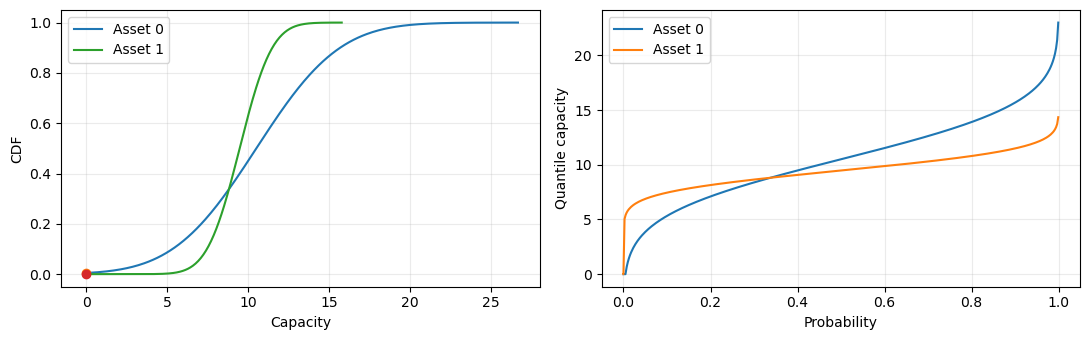

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for i, m in enumerate(marginals):
    x = np.linspace(-.2, max(1, m.mu+4*m.sd), 300)
    u = np.unique(np.r_[np.linspace(0, .999, 400), m.prob_zero])
    axes[0].plot(x, m.cdf(x), label=f'Asset {i}')
    axes[0].plot(0, m.prob_zero, 'o')
    axes[1].plot(u, m.ppf(u), label=f'Asset {i}')
axes[0].set(xlabel='Capacity', ylabel='CDF')
axes[1].set(xlabel='Probability', ylabel='Quantile capacity')
for ax in axes: ax.legend(); ax.grid(alpha=.25)
plt.tight_layout(); plt.show()

## 4. Dependence assumptions and survival functions
### Unknown dependence
At E=0 the exact worst-case AND survival is $\max(0,1-\sum_iF_i(c_i^-))$. For E>0, minimize the success-event probability over joint probabilities with fixed discretized marginal masses: this is a multi-marginal **transport LP**, not a selected copula.

Each quantile bin is rounded **down** in capacity for a lower survival bound and **up** for an upper bound. Monotonicity of the event in every capacity gives bounds for the original continuous/atomic marginals, for all dependence structures (up to LP numerical tolerances). Zero atoms are retained as separate bins, never jittered. The upper grid may include infinite capacity; its deficit is zero, so no infinite coefficient enters the LP. Bounds can be wide; they are not an exact robust probability. The solver refuses excessive Cartesian grids.

A second valid certificate allocates reserve deterministically, $r\ge0$, $\sum r_i=E$: success of all residual targets $(c_i-r_i)_+$ implies shared-reserve success. Taking the best of finitely many reserve splits and the LP lower bound stays conservative. It also ensures that constructed additive allocations remain feasible. For a single asset the exact marginal probability is used.

### Gaussian copula
Use rho=0.5 and the **non-strict event** $D\le E$. For d=1 or 2, conditional Gaussian quadrature evaluates the specified joint law, integrating across latent intervals for zero atoms. Higher dimensions use the explicitly labeled empirical fallback. This is a specified-dependence comparison, not an all-dependence guarantee. Selected allocations are evaluated on an independent sample with a 95% binomial interval.

In [4]:
def corr_eq(k, rho):
    if k < 1 or not (-1/(k-1) if k > 1 else -1) <= rho <= 1:
        raise ValueError('Invalid equicorrelation')
    return np.full((k, k), rho)+(1-rho)*np.eye(k)

def capacities(U, ms):
    return np.column_stack([m.ppf(U[:, i]) for i, m in enumerate(ms)])

Sigma = corr_eq(d, rho)
U_train = stats.norm.cdf(np.random.default_rng(seed+1).multivariate_normal(np.zeros(d), Sigma, n_train))
U_validation = stats.norm.cdf(np.random.default_rng(seed+2).multivariate_normal(np.zeros(d), Sigma, n_validation))
train_samples = {name: capacities(U_train, ms) for name, ms in portfolios.items()}
validation_samples = {name: capacities(U_validation, ms) for name, ms in portfolios.items()}

def assigned_shortfall(samples, c):
    return np.maximum(np.asarray(c)-np.asarray(samples), 0).sum(axis=-1)

def reserve_success_probability(c, E, samples):
    if E < 0 or np.any(np.asarray(c) < 0):
        raise ValueError('Nonnegative targets and reserve required')
    return float(np.mean(assigned_shortfall(samples, c) <= E))

def required_reserve(c, samples, level=alpha):
    values = np.sort(assigned_shortfall(samples, c))
    return float(values[int(np.ceil(level*len(values)))-1])

def and_survival(c, ms):
    return max(0., 1-sum(m.failure(ci).item() for m, ci in zip(ms, c)))

def simplex_directions(k, count=n_directions):
    if k == 1: return np.ones((1, 1))
    if k == 2:
        w = np.linspace(0, 1, count)
        return np.column_stack([w, 1-w])
    # Higher dimensions: reproducible direction search, not a full contour grid.
    return np.vstack([np.eye(k), np.ones((1, k))/k,
        np.random.default_rng(seed+3).dirichlet(np.ones(k), size=count)])

class RobustReserveSurvival:
    def __init__(self, ms, bins=n_transport_bins):
        from itertools import product
        self.ms = ms
        self.splits = simplex_directions(len(ms))
        lower, upper, masses = [], [], []
        for m in ms:
            # More resolution in the lower tail relevant to 90% reliability.
            edges = np.unique(np.r_[np.linspace(0, .2, int(.7*bins)+1),
                                    np.linspace(.2, 1, bins-int(.7*bins)+1), m.prob_zero])
            mass = np.diff(edges)
            low, high = m.ppf(edges[:-1]), m.ppf(edges[1:])
            # Collapse adjacent zero-atom intervals, preserving their total mass.
            merged = []
            for l, h, p in zip(low, high, mass):
                if merged and l == h == 0 and merged[-1][0] == merged[-1][1] == 0:
                    merged[-1][2] += p
                else: merged.append([l, h, p])
            low, high, mass = map(np.asarray, zip(*merged))
            lower.append(low); upper.append(high); masses.append(mass)
        counts = [len(x) for x in masses]
        states = int(np.prod(counts, dtype=object))
        if states > max_transport_states:
            raise ValueError(f'Transport needs {states:,} states; reduce d/bins or increase the explicit guard')
        index = np.array(list(product(*[range(k) for k in counts])))
        self.low = np.column_stack([lower[i][index[:, i]] for i in range(len(ms))])
        self.high = np.column_stack([upper[i][index[:, i]] for i in range(len(ms))])
        offsets = np.r_[0, np.cumsum(counts)]
        rows = np.concatenate([offsets[i]+index[:, i] for i in range(len(ms))])
        cols = np.tile(np.arange(states), len(ms))
        self.A = coo_matrix((np.ones(len(rows)), (rows, cols)), shape=(offsets[-1], states)).tocsr()
        self.mass = np.concatenate(masses)
        self.cache = {}
        self.states = states

    def split_certificate(self, c, E):
        residual = np.maximum(np.asarray(c)[None, :]-E*self.splits, 0)
        failure = sum(m.failure(residual[:, i]) for i, m in enumerate(self.ms))
        return max(0., 1-float(failure.min()))

    def _transport(self, c, E, upper=False):
        X = self.high if upper else self.low
        cost = (assigned_shortfall(X, c) <= E).astype(float)
        if cost.min() == cost.max(): return float(cost[0])
        res = linprog(cost, A_eq=self.A, b_eq=self.mass, bounds=(0, None), method='highs',
            options={'primal_feasibility_tolerance': 1e-9, 'dual_feasibility_tolerance': 1e-9})
        if not res.success: raise RuntimeError(res.message)
        return float(np.clip(res.fun, 0, 1))

    def __call__(self, c, E, upper=False):
        c = np.asarray(c, dtype=float)
        if len(c) != len(self.ms) or np.any(c < 0) or E < 0:
            raise ValueError('Invalid reserve allocation')
        if E == 0: return and_survival(c, self.ms)
        if c.sum() <= E: return 1.
        if len(c) == 1: return 1-self.ms[0].failure(max(0., c[0]-E)).item()
        key = (tuple(c), float(E), upper)
        if key not in self.cache:
            value = self._transport(c, E, upper)
            self.cache[key] = value if upper else max(value, self.split_certificate(c, E))
        return self.cache[key]

robust_survival = {name: RobustReserveSurvival(ms) for name, ms in portfolios.items()}
print('Transport states:', {name: fn.states for name, fn in robust_survival.items()})

# Conditional Gaussian integration retains latent dependence even at zero atoms.
# Uniform U0 parametrizes the complete latent interval associated with X0=0.
def gaussian_probability(c, E, ms, pooled=False):
    c = np.asarray(c, dtype=float)
    if E < 0 or np.any(c < 0): raise ValueError('Invalid targets or reserve')
    if len(ms) == 1:
        return 1-ms[0].failure(max(0., c[0]-E)).item()
    if len(ms) != 2: raise ValueError('Quadrature engine is implemented for d=1 or 2')
    m0, m1 = ms
    if pooled:
        b = float(c.sum()-E)
        if b <= 0: return 1.
        breaks = [m0.prob_zero, float(m0.cdf(b))]
    else:
        if c.sum() <= E: return 1.
        breaks = [m0.prob_zero]+[float(m0.cdf(x)) for x in (c[0], c[0]-E, c.sum()-E) if x >= 0]
    def integrand(u):
        x0 = max(0., m0.mu+m0.sd*ndtri(u)) if m0.asset_type == 'ordinary' else m0.ppf(u).item()
        if pooled:
            threshold = b-x0
        else:
            deficit0 = max(c[0]-x0, 0.)
            if deficit0 > E: return 0.
            threshold = c[1]-(E-deficit0)
        if threshold <= 0: return 1.
        f = ndtr((threshold-m1.mu)/m1.sd) if m1.asset_type == 'ordinary' else m1.failure(threshold).item()
        if f <= 0: return 1.
        if f >= 1: return 0.
        return ndtr((rho*ndtri(u)-ndtri(f))/np.sqrt(1-rho*rho))
    points = sorted(set([0., 1.]+[x for x in breaks if 0 < x < 1]))
    return float(np.clip(sum(quad(integrand, lo, hi, epsabs=2e-7, epsrel=2e-7,
        limit=100)[0] for lo, hi in zip(points[:-1], points[1:])), 0, 1))

# General-d empirical fallback is explicitly distinguished from the default quadrature.
gaussian_engine = 'quadrature' if d <= 2 else 'empirical'
gaussian_survival = {
    name: ((lambda c, E, ms=ms: gaussian_probability(c, E, ms)) if gaussian_engine == 'quadrature'
           else (lambda c, E, name=name: reserve_success_probability(c, E, train_samples[name])))
    for name, ms in portfolios.items()}


Transport states: {'ordinary': 441}


## 5. Stage 1: Robust aggregate bid (pooled benchmark)
Retain Case5's RA workflow as a **separate pooled benchmark**. Its lower/upper numerical bracket is not used as the assigned-deficit survival function. For the Gaussian comparison, the pooled bid uses conditional quadrature for d <= 2 and an empirical reliable lower-tail capacity order statistic otherwise. Both pooled benchmarks shift by E. Quantile conventions at atoms can distinguish a VaR endpoint from a largest reliable bid; the RA curve is explicitly a numerical reference.

In [5]:
def reliable_lower_capacity(values):
    ordered = np.sort(values)
    return float(ordered[len(ordered)-int(np.ceil(alpha*len(ordered)))])

bids = {}
for name, ms in portfolios.items():
    lower, upper = ra.bounds_VaR(eps, [m.ppf for m in ms], method='lower',
        num_steps=num_steps, abstol=1e-8)
    gaussian_pooled = reliable_lower_capacity(train_samples[name].sum(axis=1))
    if gaussian_engine == 'quadrature':
        lo, hi = 0., float(train_samples[name].sum(axis=1).max())+1
        while hi-lo > bid_tolerance:
            mid = (lo+hi)/2
            if gaussian_probability(np.r_[mid, np.zeros(d-1)], 0., ms, pooled=True) >= alpha:
                lo = mid
            else: hi = mid
        gaussian_pooled = lo
    bids[name] = dict(ra_lower=float(lower[0]), ra_upper=float(upper[0]),
                      gaussian_pooled=gaussian_pooled)
display(pd.DataFrame(bids).T)

,ra_lower,ra_upper,gaussian_pooled
ordinary,11.064412,11.067232,13.540864


## 6. Stage 2: Allocation with shared reserve
Optimize $\max_{c\ge0}\sum_i c_i$ subject to $S_E(c)\ge\alpha$. Write $c=bw$, $w$ on the unit simplex. Along each direction survival is nonincreasing in b, so bisection finds the largest feasible bid to the stated capacity tolerance. Search all configured directions, and explicitly include baseline-plus-E and previous-solution-plus-increment allocations. This is a **best-found directional search**, not a certificate of continuous global optimality. For robust optimization, constrain the conservative survival lower bound; the true robust bid may be higher.

Targets include the battery contribution. Additive candidates are constructed by adding E to one target and are checked, not merely drawn as a reference. Previous-level candidates make the feasible lower bid at least the preceding feasible bid plus the reserve increment, up to numerical tolerances. Default Gaussian results constrain the quadrature probability with numerical integration tolerance; the higher-dimensional empirical fallback constrains training coverage only. Independent validation does not automatically certify population reliability.

In [6]:
# Case5's zero-reserve robust joint-bid solver, retained verbatim.
from scipy.sparse import lil_matrix
n_grid_bid = 120

def failures(c, ms):
    return np.array([m.failure(max(0., ci)).item() for ci, m in zip(c, ms)])

def _options(ms, mode, n_grid):
    # Each option is (committed capacity, strict shortfall probability).
    result = []
    for m in ms:
        p0 = m.prob_zero
        options = [(0., 0.)]  # Atomic point at c=0 must have zero shortfall cost.
        if mode == 'joint':
            if p0 < eps-1e-9:
                levels = np.linspace(p0+1e-9, eps, n_grid)
            else:
                levels = np.array([])
        elif mode == 'fixed':
            low = p0+1e-9
            mid = max(0.20, low)
            n_low = int(0.65*n_grid)
            levels = np.r_[np.linspace(low, mid, n_low),
                            np.linspace(mid, 0.995, n_grid-n_low)] if low < 0.995 else np.array([])
        else:
            raise ValueError('Unrecognized allocation optimization')
        for p in np.unique(levels):
            if not p0 < p < 1.:
                continue
            c = float(m.ppf(p))
            if np.isfinite(c) and c > 1e-9:
                options.append((c, float(m.failure(c))))
        result.append(options)
    return result

def _discrete_allocation(ms, mode, bid=None, n_grid=120, time_limit=None):
    options = _options(ms, mode, n_grid)
    n_assets = len(ms)
    counts = [len(x) for x in options]
    cap = np.array([x[0] for options_i in options for x in options_i])
    prob = np.array([x[1] for options_i in options for x in options_i])
    total = len(cap)
    A = lil_matrix((n_assets+1, total), dtype=float)
    start = 0
    for i, cnt in enumerate(counts):
        A[i, start:start+cnt] = 1.
        start += cnt
    if mode == 'joint':
        A[-1, :] = prob
        last_lb, last_ub = -np.inf, eps
        objective = -cap
    else:
        A[-1, :] = cap
        last_lb, last_ub = bid, np.inf
        objective = prob
    lb = np.r_[np.ones(n_assets), last_lb]
    ub = np.r_[np.ones(n_assets), last_ub]
    res = milp(objective, integrality=np.ones(total, dtype=int),
        bounds=Bounds(np.zeros(total), np.ones(total)),
        constraints=LinearConstraint(A.tocsr(), lb, ub),
        options={'time_limit': milp_time_limit if time_limit is None else time_limit,
                 'mip_rel_gap': 1e-5})
    if res.x is None:
        raise RuntimeError(f'MILP has no incumbent: {res.message}')
    # A feasible integer selection: one column option for each asset.
    selected = []
    start = 0
    for count in counts:
        sub = res.x[start:start+count]
        k = int(np.argmax(sub))
        if sub[k] < 1-1e-5:
            raise RuntimeError('MILP did not return a valid integral incumbent')
        selected.append(start+k)
        start += count
    c = cap[selected]
    fail = failures(c, ms)
    if mode == 'joint' and fail.sum() > eps+1e-8:
        raise RuntimeError('No-redispatch candidate violates the risk budget')
    if mode == 'fixed' and c.sum() < bid-1e-7:
        raise RuntimeError('Fixed-bid candidate falls short of the aggregate bid')
    return c, dict(status=res.message, mip_gap=getattr(res, 'mip_gap', None))

def _improve_joint(ms, c):
    # Polish capacities through failure-probability coordinates on the MILP active set.
    active = np.flatnonzero(c > 1e-9)
    if len(active) == 0:
        return c
    floor = np.array([ms[i].prob_zero for i in active])
    p_start = failures(c, ms)[active]
    if floor.sum() >= eps:
        return c
    def objective(p):
        return -sum(float(ms[i].ppf(v)) for i, v in zip(active, p))
    res = minimize(objective, p_start,
        bounds=list(zip(floor+1e-10, np.full(len(active), eps))),
        constraints=[dict(type='ineq', fun=lambda p: eps-p.sum())],
        method='SLSQP', options={'ftol': 1e-11, 'maxiter': 400})
    if np.any(~np.isfinite(res.x)):
        return c
    p = np.clip(res.x, floor+1e-10, eps)
    # Numerical feasibility projection even if SLSQP reports a line-search issue.
    if p.sum() > eps:
        p = floor+ (p-floor)*(eps-floor.sum())/(p-floor).sum()
    candidate = np.zeros(len(ms))
    candidate[active] = [ms[i].ppf(v).item() for i, v in zip(active, p)]
    if failures(candidate, ms).sum() <= eps+1e-9 and candidate.sum() > c.sum()+1e-8:
        return candidate
    return c


zero_reserve_baselines = {}
for name, ms in portfolios.items():
    c0, info = _discrete_allocation(ms, 'joint', n_grid=n_grid_bid)
    c0 = _improve_joint(ms, c0)
    zero_reserve_baselines[name] = dict(c=c0, b_joint=float(c0.sum()), solver=info)
display(pd.DataFrame({name: {'b_joint_zero_reserve': x['b_joint'],
    'robust_survival': and_survival(x['c'], portfolios[name])}
    for name, x in zero_reserve_baselines.items()}).T)


,b_joint_zero_reserve,robust_survival
ordinary,11.065823,0.9


In [7]:
directions = simplex_directions(d)
search_upper = max(float(X.sum(axis=1).max()) for X in train_samples.values())+float(E_values.max())+1

def optimize_bid_with_reserve(E, survival, baseline=None, previous=None):
    candidates = [np.zeros(d)]
    for w in directions:
        lo, hi = 0., search_upper
        if survival(hi*w, E) >= alpha:
            raise RuntimeError('Search bracket too small: increase search_upper')
        while hi-lo > bid_tolerance:
            mid = (lo+hi)/2
            if survival(mid*w, E) >= alpha+prob_tolerance:
                lo = mid
            else: hi = mid
        candidates.append(lo*w)
    if baseline is not None:
        candidates.extend(baseline+E*np.eye(d))
    if previous is not None:
        old_E, old_c = previous
        candidates.extend(old_c+(E-old_E)*np.eye(d))
    feasible = [c for c in candidates if survival(c, E) >= alpha-prob_tolerance]
    c = max(feasible, key=lambda c: c.sum()).copy()
    return dict(c=c, b_joint=float(c.sum()), probability=float(survival(c, E)),
                status='Feasible best-found direction/additive candidate')

allocations, rows = {}, []
for name, ms in portfolios.items():
    for dependence in ('robust', 'gaussian'):
        fn = robust_survival[name] if dependence == 'robust' else gaussian_survival[name]
        baseline, previous = None, None
        for E in E_values:
            if E == 0 and dependence == 'robust':
                c0 = zero_reserve_baselines[name]['c'].copy()
                result = dict(c=c0, b_joint=float(c0.sum()), probability=fn(c0, 0.),
                              status='Case5 zero-reserve MILP plus active-set polishing')
            else:
                result = optimize_bid_with_reserve(float(E), fn, baseline, previous)
            if baseline is None: baseline = result['c'].copy()
            previous = (float(E), result['c'].copy())
            allocations[name, dependence, float(E)] = result
            c = result['c']
            D = assigned_shortfall(validation_samples[name], c)
            successes = int(np.count_nonzero(D <= E))
            interval = stats.binomtest(successes, len(D)).proportion_ci(confidence_level=.95)
            low = result['probability']
            high = robust_survival[name](c, E, upper=True) if dependence == 'robust' else np.nan
            if dependence == 'robust' and high < low-1e-7:
                raise RuntimeError('Transport/split lower bound exceeds the upper bound')
            rows.append(dict(scenario=name, dependence=dependence, E=float(E),
                b_joint=result['b_joint'], additive_bid=float(baseline.sum()+E),
                gain_above_additive=float(result['b_joint']-baseline.sum()-E),
                pooled_bid=float((bids[name]['ra_lower'] if dependence == 'robust'
                                  else bids[name]['gaussian_pooled'])+E),
                optimization_probability=low, robust_probability_upper=high,
                gaussian_validation_probability=successes/len(D),
                validation_ci_low=interval.low, validation_ci_high=interval.high,
                mean_reserve_used=float(np.minimum(D, E).mean()),
                uncovered_probability=float(np.mean(D > E)),
                mean_uncovered_shortfall=float(np.maximum(D-E, 0).mean()),
                allocation=c.copy(), solver_status=result['status']))
            print(f'{name}, {dependence}, E={E:.3f}: b_joint={result["b_joint"]:.4f}, '
                  f'optimization survival={low:.4%}', flush=True)

reserve_results = pd.DataFrame(rows)
display(reserve_results)

ordinary, robust, E=0.000: b_joint=11.0658, optimization survival=90.0000%


ordinary, robust, E=1.064: b_joint=12.1303, optimization survival=90.0000%


ordinary, robust, E=2.129: b_joint=13.1947, optimization survival=90.0000%


ordinary, robust, E=3.193: b_joint=14.2592, optimization survival=90.0000%


ordinary, robust, E=4.258: b_joint=15.3236, optimization survival=90.0000%


ordinary, robust, E=5.322: b_joint=16.3880, optimization survival=90.0000%


... (6 outputs left out)

ordinary, gaussian, E=4.258: b_joint=17.7334, optimization survival=90.0034%


ordinary, gaussian, E=5.322: b_joint=18.8458, optimization survival=90.0047%


ordinary, gaussian, E=6.387: b_joint=19.9237, optimization survival=90.0029%


,scenario,dependence,E,b_joint,additive_bid,gain_above_additive,pooled_bid,optimization_probability,robust_probability_upper,gaussian_validation_probability,validation_ci_low,validation_ci_high,mean_reserve_used,uncovered_probability,mean_uncovered_shortfall,allocation,solver_status
0,ordinary,robust,0.000000,11.065823,11.065823,0.000000e+00,11.064412,0.900000,0.900000,0.91050,0.907964,0.912988,0.000000,0.08950,0.145616,"[4.720404505713228, 6.345418022546819]",Case5 zero-reserve MILP plus active-set polishing
1,ordinary,robust,1.064444,12.130267,12.130267,1.776357e-15,12.128856,0.900000,0.914286,0.92150,0.919108,0.923843,0.108800,0.07850,0.139452,"[5.784848570622831, 6.345418022546819]",Feasible best-found direction/additive candidate
2,ordinary,robust,2.128888,13.194711,13.194711,1.776357e-15,13.193301,0.900000,0.914286,0.94668,0.944675,0.948633,0.303021,0.05332,0.080439,"[4.720404505713228, 8.474306152366026]",Feasible best-found direction/additive candidate
3,ordinary,robust,3.193332,14.259155,14.259155,1.776357e-15,14.257745,0.900000,0.914286,0.92278,0.920406,0.925105,0.502614,0.07722,0.138943,"[7.913736700442037, 6.345418022546819]",Feasible best-found direction/additive candidate
4,ordinary,robust,4.257776,15.323599,15.323599,1.776357e-15,15.322189,0.900000,0.914286,0.94976,0.947809,0.951659,1.406184,0.05024,0.076997,"[4.720404505713228, 10.603194282185232]",Feasible best-found direction/additive candidate
5,ordinary,robust,5.322220,16.388043,16.388043,1.776357e-15,16.386633,0.900000,0.914286,0.92278,0.920406,0.925105,1.257984,0.07722,0.138943,"[10.042624830261243, 6.345418022546819]",Feasible best-found direction/additive candidate
6,ordinary,robust,6.386664,17.452487,17.452487,0.000000e+00,17.451077,0.900000,0.914286,0.92278,0.920406,0.925105,1.799118,0.07722,0.138943,"[11.107068895170846, 6.345418022546819]",Feasible best-found direction/additive candidate
7,ordinary,gaussian,0.000000,11.371020,11.371020,0.000000e+00,13.540864,0.900035,NaN,0.90128,0.898632,0.903881,0.000000,0.09872,0.159449,"[4.832683641877759, 6.538336691952262]",Feasible best-found direction/additive candidate
8,ordinary,gaussian,1.064444,13.377333,12.435464,9.418684e-01,14.605308,0.900047,NaN,0.90098,0.898329,0.903585,0.152243,0.09902,0.171557,"[5.685366448255583, 7.691966371169317]",Feasible best-found direction/additive candidate
9,ordinary,gaussian,2.128888,15.104831,13.499908,1.604923e+00,15.669752,0.900020,NaN,0.90096,0.898308,0.903565,0.393112,0.09904,0.201634,"[6.79717399757951, 8.307657108152734]",Feasible best-found direction/additive candidate


### Survival contour in allocation space
Plot the computed survival function and its 90% boundary for selected reserve levels, with the maximizing candidate and the line $\sum c_i=b_{joint}$. Robust contours are contours of a **certified conservative lower probability bound**, not a claim to know the exact robust contour. Gaussian contours use the configured quadrature or empirical probability engine. If a probability atom skips exactly 90%, the contour interpolation is a grid visualization of the feasible boundary, not an exact equality solution. The 2D figure is skipped when d differs from 2.

C:\Users\manis\AppData\Local\Temp\ipykernel_13424\2685265026.py:134: IntegrationWarning: Extremely bad integrand behavior occurs at some points of the
  integration interval.
  return float(np.clip(sum(quad(integrand, lo, hi, epsabs=2e-7, epsrel=2e-7,


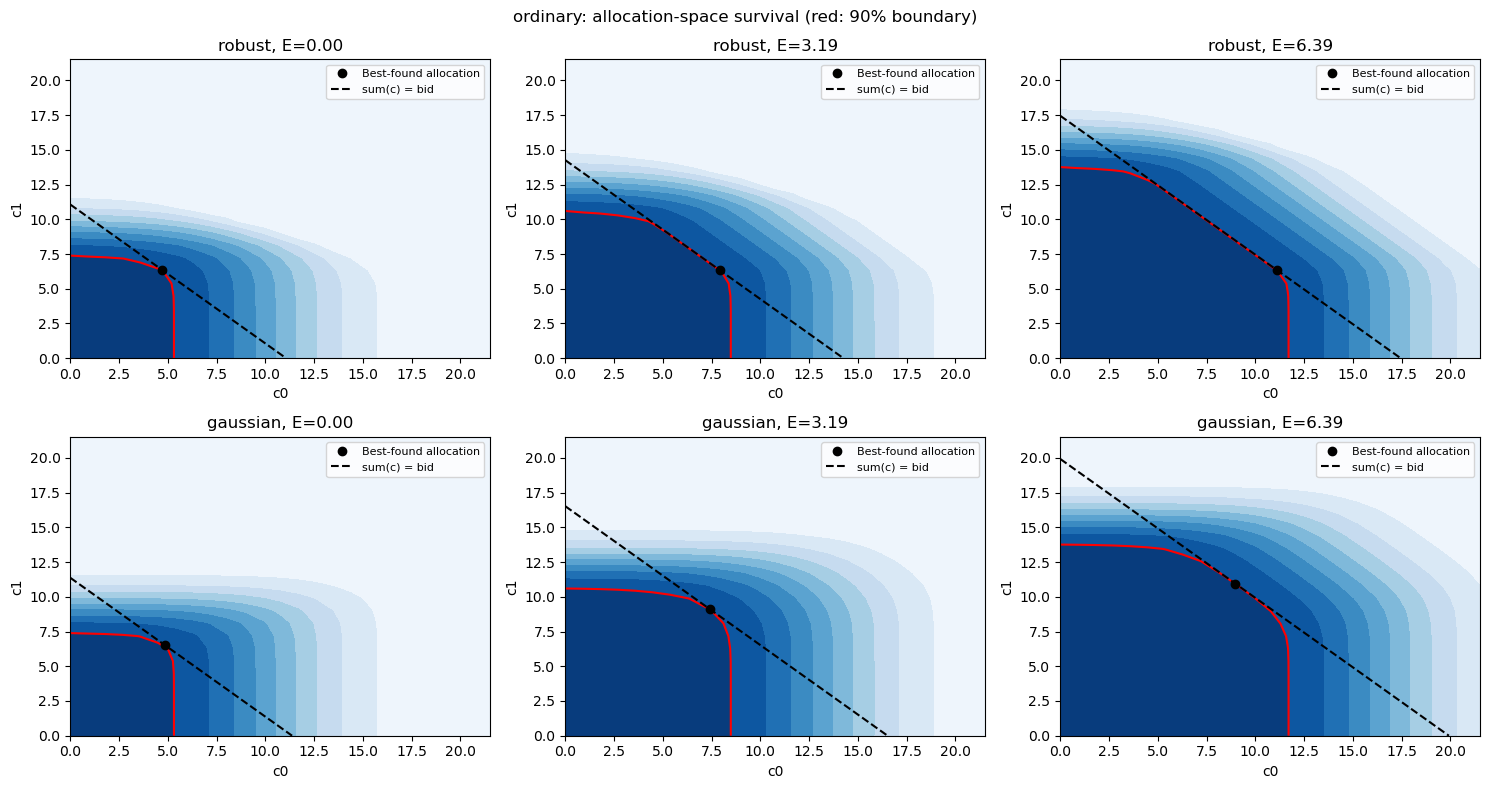

In [8]:
contour_data = {}
if d == 2:
    chosen_E = E_values[[0, len(E_values)//2, -1]]
    for name in portfolios:
        fig, axes = plt.subplots(2, len(chosen_E), figsize=(15, 8), squeeze=False)
        limit = 1.08*reserve_results[reserve_results.scenario == name]['b_joint'].max()
        grid = np.linspace(0, limit, n_contour)
        C1, C2 = np.meshgrid(grid, grid)
        for row, dependence in enumerate(('robust', 'gaussian')):
            fn = robust_survival[name] if dependence == 'robust' else gaussian_survival[name]
            for col, E in enumerate(chosen_E):
                Z = np.array([fn(c, float(E)) for c in zip(C1.ravel(), C2.ravel())]).reshape(C1.shape)
                contour_data[name, dependence, float(E)] = (grid, Z)
                ax = axes[row, col]
                ax.contourf(C1, C2, Z, levels=np.linspace(0, 1, 11), cmap='Blues', vmin=0, vmax=1)
                if Z.min() < alpha < Z.max(): ax.contour(C1, C2, Z, levels=[alpha], colors='red')
                result = allocations[name, dependence, float(E)]
                c, b = result['c'], result['b_joint']
                ax.plot(c[0], c[1], 'ko', label='Best-found allocation')
                ax.plot([0, b], [b, 0], 'k--', label='sum(c) = bid')
                ax.set(xlabel='c0', ylabel='c1', title=f'{dependence}, E={E:.2f}', xlim=(0, limit), ylim=(0, limit))
                ax.legend(fontsize=8)
        fig.suptitle(f'{name}: allocation-space survival (red: 90% boundary)')
        plt.tight_layout(); plt.show()

### Fixed-bid allocation
For a specified bid, allocations sum to that bid exactly. The default fixed bid is the no-reserve Gaussian-copula bid, so the robust and Gaussian comparisons evaluate the **same** target sum. Search for an allocation with minimum required E on the same direction grid. For robust calculations this gives a sufficient reserve, because the lower survival bound is constrained. For Gaussian samples it uses the empirical order statistic satisfying coverage, without interpolation across atoms. The interval endpoint E is included in success.

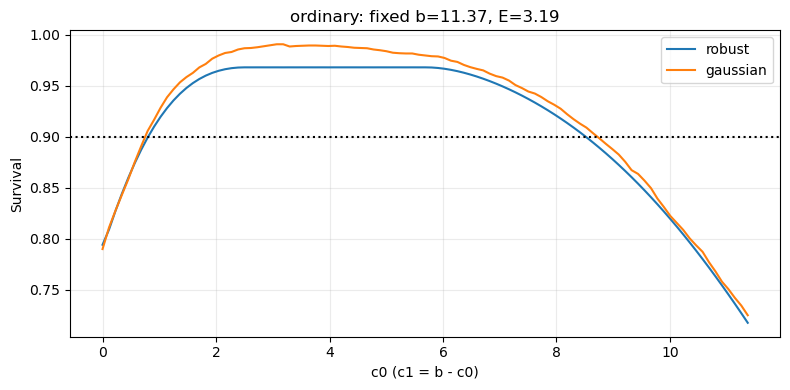

,c,bid,E_available,E_required,probability,feasible,scenario,dependence
0,"[4.832683641877759, 6.538336691952262]",11.37102,3.193332,0.305374,0.968069,True,ordinary,robust
1,"[4.548408133532009, 6.822612200298012]",11.37102,3.193332,0.000000,0.987061,True,ordinary,gaussian


In [9]:
def allocate_bid_with_reserve(b, E, survival, samples=None):
    candidates = b*directions
    required = []
    for c in candidates:
        if samples is not None:
            needed = required_reserve(c, samples)
        else:
            lo, hi = 0., b
            if survival(c, 0.) >= alpha: needed = 0.
            else:
                while hi-lo > bid_tolerance:
                    mid = (lo+hi)/2
                    if survival(c, mid) >= alpha: hi = mid
                    else: lo = mid
                needed = hi
        required.append(needed)
    i = int(np.argmin(required))
    return dict(c=candidates[i], bid=b, E_available=E, E_required=float(required[i]),
        probability=float(survival(candidates[i], E)), feasible=bool(survival(candidates[i], E) >= alpha))

fixed_bid_results = []
fixed_bid_curves = {}
for name in portfolios:
    b = allocations[name, 'gaussian', 0.]['b_joint']
    E = float(E_values[len(E_values)//2])
    for dependence in ('robust', 'gaussian'):
        fn = robust_survival[name] if dependence == 'robust' else (
            lambda c, E: reserve_success_probability(c, E, train_samples[name]))
        result = allocate_bid_with_reserve(b, E, fn,
            samples=train_samples[name] if dependence == 'gaussian' and gaussian_engine == 'empirical' else None)
        result.update(scenario=name, dependence=dependence)
        fixed_bid_results.append(result)
        if d == 2:
            c0 = np.linspace(0, b, 101)
            curve = np.array([fn([x, b-x], E) for x in c0])
            fixed_bid_curves[name, dependence] = (c0, curve)
    if d == 2:
        fig, ax = plt.subplots(figsize=(8, 4))
        for dependence in ('robust', 'gaussian'):
            x, y = fixed_bid_curves[name, dependence]
            ax.plot(x, y, label=dependence)
        ax.axhline(alpha, color='black', linestyle=':')
        ax.set(xlabel='c0 (c1 = b - c0)', ylabel='Survival', title=f'{name}: fixed b={b:.2f}, E={E:.2f}')
        ax.legend(); ax.grid(alpha=.25); plt.tight_layout(); plt.show()
display(pd.DataFrame(fixed_bid_results))

## 7. Scenario comparison and interpretation
Compare optimized assigned-target bids with their own zero-reserve/additive baselines and the separate pooled benchmark. The robust curve is a feasible lower estimate; the Gaussian curve is a specified-copula best-found bid (quadrature by default). They have different dependence scopes and should not be described as two estimates of the same probability.

Validation probabilities, reserve-use means and uncovered-shortfall statistics in the table always refer to the **Gaussian validation sample**, including for allocations chosen robustly. They are not worst-case reserve-use moments. The binomial interval quantifies sampling uncertainty only, not optimizer bias or transport discretization error. Results are not a population 90% certification merely because the training survival meets 90%.

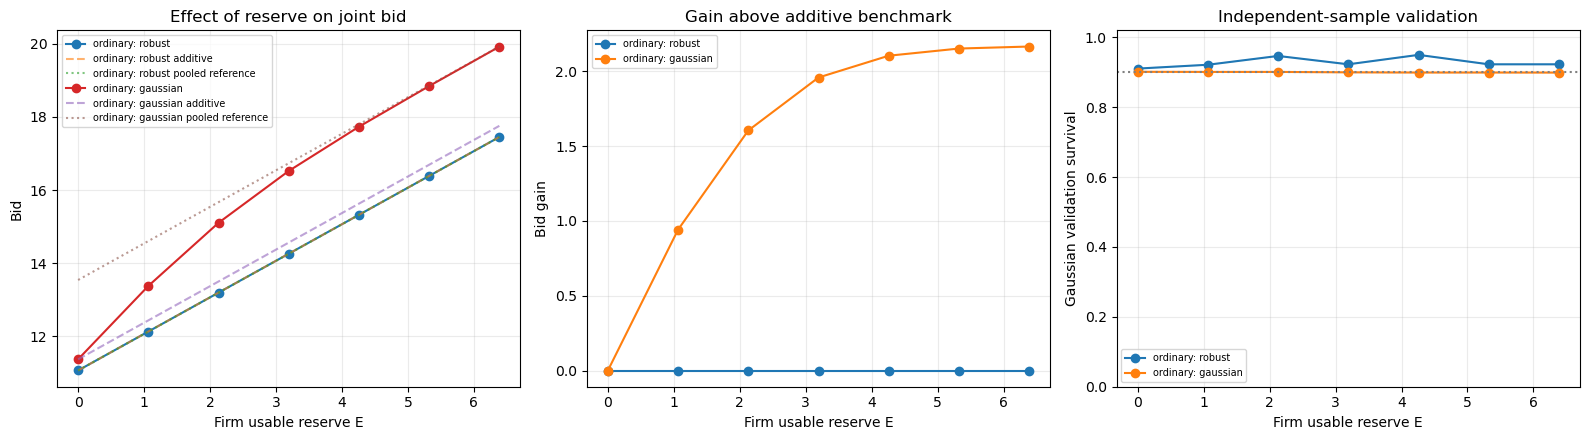

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for (name, dependence), data in reserve_results.groupby(['scenario', 'dependence'], sort=False):
    label = f'{name}: {dependence}'
    axes[0].plot(data.E, data.b_joint, 'o-', label=label)
    axes[0].plot(data.E, data.additive_bid, '--', alpha=.6, label=f'{label} additive')
    axes[0].plot(data.E, data.pooled_bid, ':', alpha=.6, label=f'{label} pooled reference')
    axes[1].plot(data.E, data.gain_above_additive, 'o-', label=label)
    axes[2].plot(data.E, data.gaussian_validation_probability, 'o-', label=label)
    axes[2].fill_between(data.E, data.validation_ci_low, data.validation_ci_high, alpha=.12)
axes[0].set(ylabel='Bid', title='Effect of reserve on joint bid')
axes[1].set(ylabel='Bid gain', title='Gain above additive benchmark')
axes[2].set(ylabel='Gaussian validation survival', title='Independent-sample validation', ylim=(0, 1.02))
axes[2].axhline(alpha, color='grey', linestyle=':')
for ax in axes: ax.set_xlabel('Firm usable reserve E'); ax.grid(alpha=.25); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

# Save reusable numerical results and a standalone plot; no optimization is needed to reopen them.
output = project_root/'figures'
output.mkdir(exist_ok=True)
fig.savefig(output/'Case5_with_reserve_bid_vs_E.png', dpi=180, bbox_inches='tight')
reserve_results.assign(allocation=reserve_results.allocation.map(lambda c: c.tolist())).to_csv(
    output/'Case5_with_reserve_results.csv', index=False)

### Realized-capacity space (different from the allocation contour)
For one fixed c and E, color capacities x for which the battery covers all assigned deficits. Surplus pooling is not allowed. This geometric success region has no probability interpretation until a dependence model is supplied.

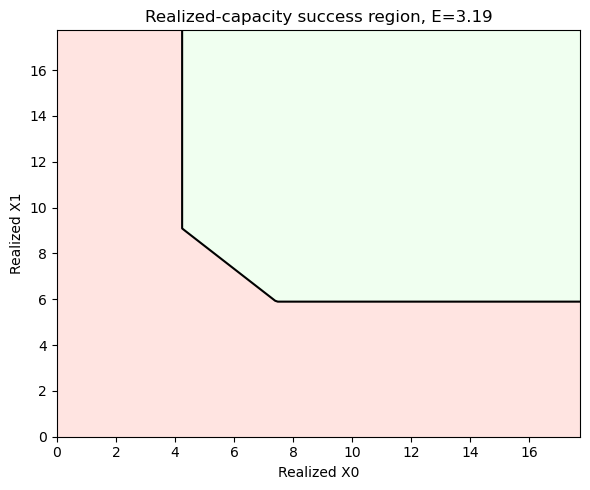

In [11]:
if d == 2:
    E = float(E_values[len(E_values)//2])
    c = allocations[scenario, 'gaussian', E]['c']
    x = np.linspace(0, max(c)*1.6+E, 200)
    X1, X2 = np.meshgrid(x, x)
    deficit = np.maximum(c[0]-X1, 0)+np.maximum(c[1]-X2, 0)
    fig, ax = plt.subplots(figsize=(6, 5))
    ax.contourf(X1, X2, (deficit <= E).astype(float), levels=[-.5, .5, 1.5], colors=['mistyrose', 'honeydew'])
    ax.contour(X1, X2, deficit, levels=[E], colors='black')
    ax.set(xlabel='Realized X0', ylabel='Realized X1', title=f'Realized-capacity success region, E={E:.2f}')
    plt.tight_layout(); plt.show()

### Validation and numerical sensitivity
Checks cover shared reserve, the AND limit, strict marginal failure at zero, monotonicity, additive feasibility, exact empirical order-statistic coverage, fixed-bid equality, the one-asset identity, and lower/upper probability bounds. Sensitivity recomputes selected allocations with a finer transport grid; it does not reoptimize or certify global optimality. The non-strict event is evaluated without artificial tolerance; LP/feasibility tolerances are numerical acceptance tolerances, not extra battery energy.

In [12]:
def validate():
    assert assigned_shortfall([[5, 3]], [6, 4])[0] == 2
    assert reserve_success_probability([6, 4], 1, [[5, 3]]) == 0
    assert reserve_success_probability([6, 4], 2, [[5, 3]]) == 1
    assert reserve_success_probability([6, 4], 0, [[8, 2]]) == 0
    assert sum([8, 2]) == sum([6, 4])  # pooling would succeed
    assert reserve_success_probability([2, 2], 2, [[10, 0], [0, 10]]) == 1
    for name, ms in portfolios.items():
        fn, samples = robust_survival[name], train_samples[name]
        c = allocations[name, 'robust', 0.]['c']
        assert np.isclose(fn(c, 0), and_survival(c, ms))
        assert reserve_success_probability(c, 0, samples) == np.mean(np.all(samples >= c, axis=1))
        values = [fn(c, float(E)) for E in E_values]
        assert np.all(np.diff(values) >= -1e-7)
        E = float(E_values[len(E_values)//2])
        assert fn(c+.1, E) <= fn(c, E)+1e-7
        assert fn(c+E*np.eye(d)[0], E) >= and_survival(c, ms)-1e-7
        needed = required_reserve(c, samples)
        assert reserve_success_probability(c, needed, samples) >= alpha
        for dep in ('robust', 'gaussian'):
            data = reserve_results[(reserve_results.scenario == name)&(reserve_results.dependence == dep)]
            assert np.all(np.diff(data.b_joint) >= -bid_tolerance)
            assert np.all(data.b_joint >= data.additive_bid-bid_tolerance)
            assert np.all(data.optimization_probability >= alpha-prob_tolerance)
            for E in E_values:
                result = allocations[name, dep, float(E)]
                assert np.all(result['c'] >= 0) and np.isclose(result['c'].sum(), result['b_joint'])
    for result in fixed_bid_results:
        assert np.isclose(result['c'].sum(), result['bid'])
    m = marginals[0]
    one = RobustReserveSurvival([m])
    q = m.ppf(eps).item()
    for E in (0., .5, 2.):
        assert one([q+E], E) >= alpha-1e-12
        assert np.isclose(one([q+E], E), one([q], 0.), atol=1e-12)
    print('Validation passed: shared reserve, AND baseline, monotonicity, additive candidates, and allocation feasibility.')

validate()
sensitivity = []
for name, ms in portfolios.items():
    finer = RobustReserveSurvival(ms, bins=n_transport_bins+8)
    E = float(E_values[len(E_values)//2])
    c = allocations[name, 'robust', E]['c']
    sensitivity.append(dict(scenario=name, E=E,
        lower_coarse=robust_survival[name](c, E), upper_coarse=robust_survival[name](c, E, upper=True),
        lower_fine=finer(c, E), upper_fine=finer(c, E, upper=True)))
display(pd.DataFrame(sensitivity))

Validation passed: shared reserve, AND baseline, monotonicity, additive candidates, and allocation feasibility.


,scenario,E,lower_coarse,upper_coarse,lower_fine,upper_fine
0,ordinary,3.193332,0.9,0.914286,0.9,0.915789
